# 01 · Dataset Selection & Data-Quality Checks
**Assessment tasks 1–3.** The research survey (`research/AI_Call_Center_Datasets_Benchmark.xlsx`) compared 11 datasets.
The selected dataset is **AppTek Call Center Dialogues** (`apptek-com/apptek_callcenter_dialogues`, CC BY-SA 4.0):

| Criterion | Why AppTek wins |
|---|---|
| Agent ↔ customer voice calls | 873 calls, 14 English accent groups |
| Ground-truth transcripts | Manual, verbatim, time-stamped → we can measure Whisper's accuracy (WER) |
| Speaker / role labels | Every segment is labelled `agent` / `customer` → we can measure speaker separation |
| License | CC BY-SA 4.0, public, no access request |

**Disclosure:** the calls are *role-played* (not real customers). This is stated in the README and results.

The full dataset is ~52 GB, so this notebook downloads only the metadata, selects a **stratified, reproducible sample of 20 calls** (round-robin across accents, ≤ 8 minutes, seed 42) and downloads just those audio files.

In [ ]:
# ---- Setup: open the project folder (run this cell first) ----
import os, sys
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")                       # results are saved to Drive, so they survive restarts
    PROJECT_DIR = "/content/drive/MyDrive/call-center-ai"  # <- change if your folder is elsewhere
else:
    PROJECT_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(PROJECT_DIR)
sys.path.insert(0, PROJECT_DIR)
print("Working in:", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in: /content/drive/MyDrive/call-center-ai


In [ ]:
!pip install -q huggingface_hub soundfile pandas matplotlib

## 1. Build the catalog (metadata only, no audio)

In [ ]:
from src import config
from src.data_loader import AppTekDataLoader, quality_report

loader = AppTekDataLoader(token=config.get_secret("HF_TOKEN"))  # token optional for this public dataset
catalog = loader.build_catalog()
print(f"{len(catalog)} calls, {catalog['duration'].sum() / 3600:.1f} hours, {catalog['accent_dir'].nunique()} accent groups")
catalog[["accent_dir", "domain", "duration_min", "n_segments"]].describe(include="all")

873 calls, 151.1 hours, 14 accent groups


,accent_dir,domain,duration_min,n_segments
count,873,873,873.000000,873.000000
unique,14,16,NaN,NaN
top,en-CN,entertainment,NaN,NaN
freq,79,84,NaN,NaN
mean,NaN,NaN,10.382573,108.452463
std,NaN,NaN,2.782634,42.387551
min,NaN,NaN,3.413217,29.000000
25%,NaN,NaN,8.261333,78.000000
50%,NaN,NaN,10.287550,100.000000
75%,NaN,NaN,11.892117,134.000000


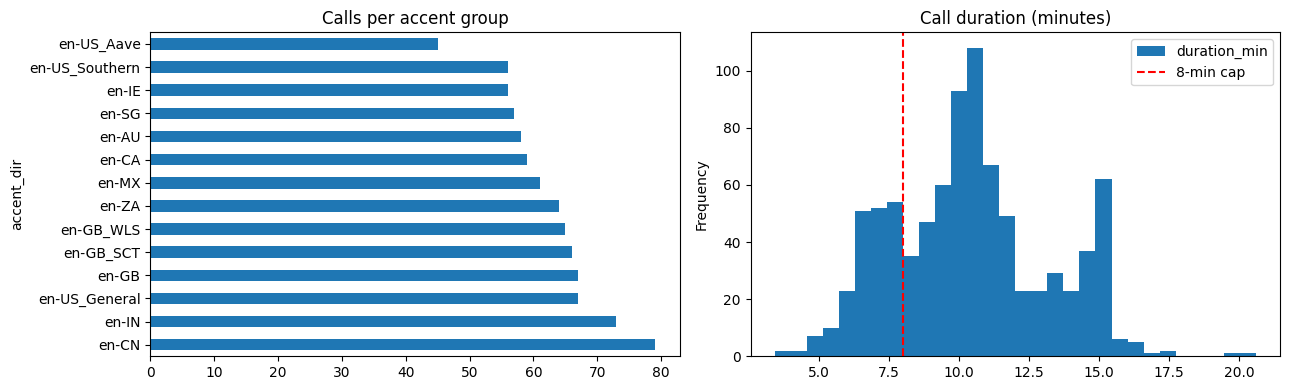

Domains: {'entertainment': 84, 'retail': 82, 'aviation': 70, 'food': 69, 'banking': 64, 'deliveryservice': 63, 'health': 57, 'travel': 57, 'hospitality': 54, 'realestate': 47, 'insurance': 42, 'agriculture': 41, 'telecom': 40, 'technology': 38, 'energy': 36, 'finance': 29}


In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
catalog["accent_dir"].value_counts().plot.barh(ax=ax[0], title="Calls per accent group")
catalog["duration_min"].plot.hist(bins=30, ax=ax[1], title="Call duration (minutes)")
ax[1].axvline(config.MAX_CALL_MINUTES, color="red", ls="--", label=f"{config.MAX_CALL_MINUTES}-min cap")
ax[1].legend(); plt.tight_layout(); plt.show()
print("Domains:", catalog["domain"].value_counts().to_dict())

## 2. Select a stratified, reproducible sample

In [ ]:
sample = loader.select_sample(catalog)   # N_CALLS, MAX_CALL_MINUTES and RANDOM_SEED come from src/config.py
sample[["call_id", "accent_dir", "domain", "duration_min", "n_segments", "file_name"]]

,call_id,accent_dir,domain,duration_min,n_segments,file_name
0,call_001,en-AU,deliveryservice,7.033333,70,audio/en_AU_DeliveryService_1586330.wav
1,call_002,en-CA,deliveryservice,7.771900,55,audio/en_CA_DeliveryService_1590620.wav
2,call_003,en-CN,technology,7.082050,51,audio/en_CN_Technology_1581926.wav
3,call_004,en-GB,realestate,7.964300,84,audio/en_GB_RealEstate_1582220.wav
4,call_005,en-GB_SCT,technology,5.613900,84,audio/en_GB_SCT_Technology_1593370.wav
5,call_006,en-GB_WLS,retail,7.421400,106,audio/en_GB_WLS_Retail_1593358.wav
6,call_007,en-IE,finance,7.596050,104,audio/en_IE_Finance_1586645.wav
7,call_008,en-IN,entertainment,6.649250,58,audio/en_IN_Entertainment_003_20250927.wav
8,call_009,en-MX,banking,6.680150,91,audio/en_MX_Banking_1588960.wav
9,call_010,en-SG,realestate,7.609083,140,audio/en_SG_RealEstate_1588810.wav


## 3. Download only the selected calls

In [ ]:
records = loader.download_sample(sample)
print(f"Downloaded {len(records)} calls to {config.AUDIO_DIR}")
print(f"Ground truth saved to {config.SAMPLE_METADATA}")

Downloaded 20 calls to /content/drive/MyDrive/call-center-ai/data/raw/audio
Ground truth saved to /content/drive/MyDrive/call-center-ai/data/raw/sample_metadata.jsonl


## 4. Data-quality checks
File readable, sample rate, audio length vs. metadata, missing roles, empty segments, both speakers present.

In [ ]:
qc = quality_report(records)
qc.to_csv(config.QUALITY_REPORT_FILE, index=False)
qc

,call_id,accent,domain,sample_rate,channels,audio_minutes,file_ok,duration_mismatch_s,n_segments,missing_role,empty_text,has_agent_and_customer
0,call_001,en-AU,deliveryservice,16000,1,7.03,True,0.0,70,0,0,True
1,call_002,en-CA,deliveryservice,16000,1,7.77,True,0.0,55,0,0,True
2,call_003,en-CN,technology,16000,1,7.08,True,0.0,51,0,0,True
3,call_004,en-GB,realestate,16000,1,7.96,True,0.0,84,0,0,True
4,call_005,en-GB_SCT,technology,16000,1,5.61,True,0.0,84,0,0,True
5,call_006,en-GB_WLS,retail,16000,1,7.42,True,0.0,106,0,0,True
6,call_007,en-IE,finance,16000,1,7.60,True,0.0,104,0,0,True
7,call_008,en-IN,entertainment,16000,1,6.65,True,0.0,58,0,0,True
8,call_009,en-MX,banking,16000,1,6.68,True,0.0,91,0,0,True
9,call_010,en-SG,realestate,16000,1,7.61,True,0.0,140,0,0,True


In [ ]:
print("Calls with problems:")
problems = qc[(~qc["file_ok"]) | (qc["missing_role"] > 0) | (~qc["has_agent_and_customer"]) | (qc["duration_mismatch_s"] > 1)]
display(problems if len(problems) else "None")
print("Sample rates found:", qc["sample_rate"].value_counts().to_dict())

Calls with problems:


'None'

Sample rates found: {16000: 20}


## 5. Listen to one call and read its ground truth

In [ ]:
from IPython.display import Audio
r = records[0]
print(r["call_id"], r["accent"], r["domain"])
for s in r["segments"][:8]:
    print(f"[{s['start']:6.1f}s] {s['role']:8s}: {s['text']}")
Audio(str(config.PROJECT_ROOT / r["audio_path"]))

Output hidden; open in https://colab.research.google.com to view.

## Notes for the README
- Copy the numbers above (calls, hours, sample rate, problems found) into `research/` → *Selection Criteria* → Data-Quality Checks.
- License: CC BY-SA 4.0 — attribute AppTek; derived transcripts in `results/` are shared under the same license.
- Audio files are **not** committed to GitHub (size); they are re-downloaded by this notebook.